> **Uyarı:** Bu içerik, SCÜ Şarkışla UBYO Doğal Dil İşleme dersi kapsamında tamamen eğitim amaçlı çevrilmiş ve derlenmiştir. Orijinal dokümantasyon kaynakları (Hugging Face LLM Course, Transformers, Datasets, Tokenizers kütüphaneleri) kendi orijinal lisanslarına (Apache 2.0, MIT, CC-BY 4.0) tabidir. Bu çalışmanın hiçbir ticari amacı yoktur.

# Bölüm 6 Red-Team: Tokenizer'ları Türkçe ile Kırmak (Kontrol + 5 Test)

## Fikir
Kursun Bölüm 6 girişi şunu söyler: *Başka bir dil için eğitilmiş bir tokenizer, yeni dilde kötü performans gösterir.* Biz bu iddiayı **ölçülebilir** hâle getirip Türkçe ile zorluyoruz. Tokenizer hataları çoğu zaman **sessizdir**: Kod hata vermez, ama model yanlış ya da eksik bir girdi görür.

## Deney düzeni
- **3 algoritma:** WordPiece (BERT), BPE (GPT-2, bayt düzeyinde), Unigram (XLNet / SentencePiece)
- **2 eğitim dili:** İngilizce derlem ([UD English-EWT](https://github.com/UniversalDependencies/UD_English-EWT), 12.544 cümle) ve Türkçe derlem ([UD Turkish-BOUN](https://github.com/UniversalDependencies/UD_Turkish-BOUN), 7.803 cümle). İkisi de CC BY-SA 4.0 lisanslıdır.
- **Toplam 6 tokenizer**, hepsi kursun 6.9 kısmındaki gibi sıfırdan ve aynı kelime dağarcığı boyutuyla (8.000) eğitilir. Böylece tek değişken **eğitim dili** olur.
- Ölçümler, eğitimde kullanılmayan **test kümeleri** üzerinde yapılır.

| Test | Bozulan şey | Kurs kısmı | Hata türü |
|---|---|---|---|
| Kontrol | Yok (her tokenizer kendi dilinde) | 6.2 | – |
| 1 | Tokenizer'ın dili ≠ metnin dili | 6.1, 6.2 | Sessiz (maliyet artışı) |
| 2 | Kelime dağarcığında olmayan karakterler | 6.6, 6.7, 6.8 | Sessiz (bilgi kaybı) |
| 3 | Standart (İngilizce) normalizasyon | 6.5 | Sessiz (anlam çakışması) |
| 4 | Görünmez ve benzer görünen karakterler | 6.5 | Sessiz (filtre atlatma) |
| 5 | Normalizasyonun tokenizer dışında yapılması | 6.3 | Sessiz (offset kayması) |

## Ortam ve veri

In [1]:
%pip install -q "tokenizers>=0.15" "transformers>=4.40" matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, unicodedata, urllib.request
from collections import defaultdict

import matplotlib.pyplot as plt
from tokenizers import Tokenizer, Regex, decoders, models, normalizers, pre_tokenizers, trainers

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.25, "axes.axisbelow": True})
RENK_EN, RENK_TR = "#2a78d6", "#eb6834"   # renk körlüğü için doğrulanmış palet

URL = "https://raw.githubusercontent.com/UniversalDependencies/{repo}/master/{dosya}"
def indir_oku(repo, dosya):
    os.makedirs("veri", exist_ok=True)
    yol = os.path.join("veri", dosya)
    if not os.path.exists(yol):
        urllib.request.urlretrieve(URL.format(repo=repo, dosya=dosya), yol)
    with open(yol, encoding="utf-8") as f:
        return [s[9:].strip() for s in f if s.startswith("# text = ")]

en_egitim = indir_oku("UD_English-EWT", "en_ewt-ud-train.conllu")
en_test   = indir_oku("UD_English-EWT", "en_ewt-ud-test.conllu")
tr_egitim = indir_oku("UD_Turkish-BOUN", "tr_boun-ud-train.conllu")
tr_test   = indir_oku("UD_Turkish-BOUN", "tr_boun-ud-test.conllu")
print(f"EN eğitim {len(en_egitim):,} / test {len(en_test):,}  |  TR eğitim {len(tr_egitim):,} / test {len(tr_test):,}")

EN eğitim 12,544 / test 2,077  |  TR eğitim 7,803 / test 979


## Hazırlık: 6 tokenizer'ı eğitmek (kurs 6.9)
Her algoritma, kursta gösterilen orijinal model yapılandırmasıyla kurulur. WordPiece için `bert-base-uncased`'in kullandığı `BertNormalizer(lowercase=True)` normalizer'ını kullanıyoruz.

In [3]:
VOCAB = 8000
def yiginlar(cumleler, n=1000):
    for i in range(0, len(cumleler), n):
        yield cumleler[i:i + n]

def wordpiece(derlem):
    t = Tokenizer(models.WordPiece(unk_token="[UNK]"))
    t.normalizer = normalizers.BertNormalizer(lowercase=True)   # bert-base-uncased ile aynı
    t.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
    t.train_from_iterator(yiginlar(derlem), trainers.WordPieceTrainer(
        vocab_size=VOCAB, special_tokens=["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"], show_progress=False))
    return t

def bpe(derlem):
    t = Tokenizer(models.BPE())
    t.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    t.decoder = decoders.ByteLevel()
    t.train_from_iterator(yiginlar(derlem), trainers.BpeTrainer(
        vocab_size=VOCAB, special_tokens=["<|endoftext|>"],
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False))
    return t

def unigram(derlem):
    t = Tokenizer(models.Unigram())
    t.normalizer = normalizers.NFKC()
    t.pre_tokenizer = pre_tokenizers.Metaspace()
    t.decoder = decoders.Metaspace()
    t.train_from_iterator(yiginlar(derlem), trainers.UnigramTrainer(
        vocab_size=VOCAB, special_tokens=["<unk>"], unk_token="<unk>", show_progress=False))
    return t

KURUCU = {"WordPiece": wordpiece, "BPE": bpe, "Unigram": unigram}
UNK = {"WordPiece": "[UNK]", "BPE": None, "Unigram": "<unk>"}
TOK = {(ad, dil): f(derlem) for ad, f in KURUCU.items() for dil, derlem in [("EN", en_egitim), ("TR", tr_egitim)]}
print("Eğitilen tokenizer'lar:", list(TOK))

def parcala(ad, tok, metin):
    # BPE'nin bayt düzeyindeki token'larını okunur hâle getirir
    if ad == "BPE":
        return [tok.decode([i]) for i in tok.encode(metin).ids]
    return tok.encode(metin).tokens

def olc(ad, tok, cumleler):
    encs = tok.encode_batch(cumleler)
    kelime = sum(len(c.split()) for c in cumleler)
    token = sum(len(e.tokens) for e in encs)
    unk = sum(e.tokens.count(UNK[ad]) for e in encs) if UNK[ad] else 0
    return {"dogurganlik": token / kelime, "token": token, "unk": unk, "unk_orani": unk / token}

Eğitilen tokenizer'lar: [('WordPiece', 'EN'), ('WordPiece', 'TR'), ('BPE', 'EN'), ('BPE', 'TR'), ('Unigram', 'EN'), ('Unigram', 'TR')]


## KONTROL: Her tokenizer kendi dilinde
Önce "sağlıklı" durumu ölçüyoruz: İngilizce tokenizer İngilizce metinde, Türkçe tokenizer Türkçe metinde. **Doğurganlık** (fertility), kelime başına düşen ortalama token sayısıdır.

In [4]:
kontrol = {}
print(f"{'Algoritma':10} {'EN tok → EN metin':>18} {'TR tok → TR metin':>18}")
for ad in KURUCU:
    a, b = olc(ad, TOK[(ad, "EN")], en_test), olc(ad, TOK[(ad, "TR")], tr_test)
    kontrol[ad] = (a, b)
    print(f"{ad:10} {a['dogurganlik']:18.2f} {b['dogurganlik']:18.2f}")

Algoritma   EN tok → EN metin  TR tok → TR metin
WordPiece                1.53               1.85
BPE                      1.61               1.99


Unigram                  1.63               1.97


**Sonuç:** Kendi dilinde kullanılan her tokenizer kelime başına yaklaşık 1,5–2 token üretiyor. Türkçe sayıların biraz daha yüksek olması normaldir, çünkü Türkçe kelimeler ek aldıkça uzar. Bu değerler bizim **referans** noktamızdır.

## Test 1: Tokenizer'ın dili ≠ metnin dili (token şişmesi)
**Ne yaptık?** İngilizce derlemde eğitilmiş tokenizer'ları Türkçe test metnine uyguladık.
**Beklenen:** Kod hata vermez ama Türkçe kelimeler çok daha fazla parçaya bölünür.

In [5]:
test1 = {}
print(f"{'Algoritma':10} {'TR tok':>8} {'EN tok':>8} {'Artış':>7}")
for ad in KURUCU:
    tr_d = kontrol[ad][1]["dogurganlik"]
    en_d = olc(ad, TOK[(ad, "EN")], tr_test)["dogurganlik"]
    test1[ad] = (tr_d, en_d)
    print(f"{ad:10} {tr_d:8.2f} {en_d:8.2f} {en_d / tr_d:6.2f}x")

kelime = "Çekoslovakyalılaştıramadıklarımızdanmışsınız"
print(f"\n'{kelime}' kaç parçaya bölünüyor?")
for ad in KURUCU:
    for dil in ["TR", "EN"]:
        p = parcala(ad, TOK[(ad, dil)], kelime)
        print(f"  {ad:9} ({dil} eğitimli): {len(p):>2} parça  {p if len(p) <= 16 else p[:16] + ['...']}")

Algoritma    TR tok   EN tok   Artış
WordPiece      1.85     2.80   1.51x
BPE            1.99     5.06   2.54x
Unigram        1.97     4.88   2.48x

'Çekoslovakyalılaştıramadıklarımızdanmışsınız' kaç parçaya bölünüyor?
  WordPiece (TR eğitimli): 13 parça  ['cek', '##os', '##lo', '##va', '##k', '##yal', '##ıl', '##ast', '##ıra', '##madık', '##larımızdan', '##mıs', '##sınız']
  WordPiece (EN eğitimli):  1 parça  ['[UNK]']
  BPE       (TR eğitimli): 13 parça  ['Çek', 'os', 'l', 'ov', 'ak', 'yalı', 'laş', 'tıra', 'madık', 'larımız', 'dan', 'mış', 'sınız']
  BPE       (EN eğitimli): 44 parça  ['�', '�', 'ek', 'os', 'l', 'ov', 'ak', 'y', 'al', '�', '�', 'la', '�', '�', 't', '�', '...']
  Unigram   (TR eğitimli): 14 parça  ['▁Çek', 'os', 'lo', 'va', 'k', 'ya', 'lı', 'laştır', 'amadı', 'k', 'larımız', 'dan', 'mış', 'sınız']
  Unigram   (EN eğitimli): 35 parça  ['▁', 'Ç', 'e', 'ko', 's', 'lo', 'v', 'a', 'k', 'y', 'al', 'ı', 'la', 'ş', 't', 'ı', '...']


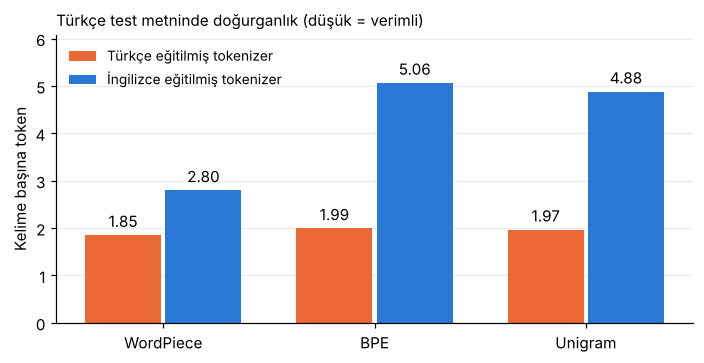

In [6]:
import numpy as np
x = np.arange(len(KURUCU)); w = 0.36
fig, ax = plt.subplots(figsize=(6.5, 3.4))
b1 = ax.bar(x - w/2 - 0.01, [test1[a][0] for a in KURUCU], w, color=RENK_TR, label="Türkçe eğitilmiş tokenizer")
b2 = ax.bar(x + w/2 + 0.01, [test1[a][1] for a in KURUCU], w, color=RENK_EN, label="İngilizce eğitilmiş tokenizer")
ax.bar_label(b1, fmt="%.2f", padding=3); ax.bar_label(b2, fmt="%.2f", padding=3)
ax.set_xticks(x, list(KURUCU)); ax.set_ylabel("Kelime başına token")
ax.set_title("Türkçe test metninde doğurganlık (düşük = verimli)", fontsize=10, loc="left")
ax.set_ylim(0, max(v[1] for v in test1.values()) * 1.2); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

In [7]:
# Pratik etkisi: 512 token'lık bir bağlam penceresine kaç Türkçe kelime sığar?
for ad in KURUCU:
    tr_d, en_d = test1[ad]
    print(f"{ad:10} Türkçe tokenizer: ~{512 / tr_d:4.0f} kelime   |   İngilizce tokenizer: ~{512 / en_d:4.0f} kelime")

WordPiece  Türkçe tokenizer: ~ 277 kelime   |   İngilizce tokenizer: ~ 183 kelime
BPE        Türkçe tokenizer: ~ 257 kelime   |   İngilizce tokenizer: ~ 101 kelime
Unigram    Türkçe tokenizer: ~ 260 kelime   |   İngilizce tokenizer: ~ 105 kelime


**Sonuç (sessiz bozulma):** BPE ve Unigram'da İngilizce tokenizer Türkçe metni yaklaşık **2,5 kat** daha fazla token'la temsil ediyor. Bu; daha yüksek hesaplama ve API maliyeti, daha yavaş çıkarım ve aynı bağlam penceresine sığan metnin yaklaşık 2,5 kat azalması anlamına geliyor. WordPiece'teki artışın daha küçük görünmesi yanıltıcıdır: Test 2'de göreceğimiz gibi bu tokenizer bazı kelimeleri tek bir `[UNK]` token'ına indirerek "kısaltıyor".

## Test 2: Kelime dağarcığında olmayan karakterler (`[UNK]` kaybı)
**Ne yaptık?** İngilizce tokenizer'ların Türkçeye özgü `ı, ğ, ş` gibi karakterlerle nasıl başa çıktığını ölçtük.
**Beklenen:** Kursun 6.7 kısmına göre WordPiece, bir kelimenin herhangi bir parçasını bulamazsa **kelimenin tamamını** `[UNK]` yapar. BPE ise yalnızca bilinmeyen karakteri `[UNK]` yapar; bayt düzeyinde BPE ise hiçbir zaman `[UNK]` üretmez.

In [8]:
print(f"{'Algoritma':10} {'UNK token':>10} {'Toplam':>8} {'UNK oranı':>10}")
test2 = {}
for ad in KURUCU:
    r = olc(ad, TOK[(ad, "EN")], tr_test)
    test2[ad] = r
    print(f"{ad:10} {r['unk']:10,} {r['token']:8,} {100 * r['unk_orani']:9.2f}%")

# Tamamen kaybolan kelimeler: WordPiece'in tek bir [UNK] ürettiği kelimeler
wp_en = TOK[("WordPiece", "EN")]
kelimeler = sorted({k for c in tr_test for k in c.split()})
kayip = [k for k in kelimeler if wp_en.encode(k).tokens == ["[UNK]"]]
print(f"\nTest kümesindeki {len(kelimeler):,} farklı kelimeden {len(kayip):,} tanesi (%{100 * len(kayip) / len(kelimeler):.1f}) tamamen [UNK] oldu.")
print("Örnekler:", kayip[:12])
print(f"Kaybolan kelimelerin %{100 * sum(('ı' in k) or ('I' in k) for k in kayip) / len(kayip):.1f}'i 'ı' veya 'I' harfi içeriyor.")

Algoritma   UNK token   Toplam  UNK oranı
WordPiece       2,127   27,932      7.61%
BPE                 0   50,577      0.00%
Unigram             0   48,731      0.00%

Test kümesindeki 6,686 farklı kelimeden 1,231 tanesi (%18.4) tamamen [UNK] oldu.
Örnekler: ['Acımasızlığı', 'Afrikalı', 'Alayı', 'Almayalım', 'Altı', 'Anlamı', 'Aralarında', 'Artık', 'Aslanın', 'Asıl', 'Ayaklarınızdan', 'Ayrıca']
Kaybolan kelimelerin %100.0'i 'ı' veya 'I' harfi içeriyor.


In [9]:
for k in ["ışık", "ağaç", "Göğüs", "kılıç"]:
    print(f"{k:7} → WordPiece: {wp_en.encode(k).tokens!s:24} Unigram: {TOK[('Unigram', 'EN')].encode(k).tokens!s:28} BPE: {parcala('BPE', TOK[('BPE', 'EN')], k)}")

ışık    → WordPiece: ['[UNK]']                Unigram: ['▁', 'ışı', 'k']            BPE: ['�', '�', '�', '�', '�', '�', 'k']
ağaç    → WordPiece: ['ag', '##ac']           Unigram: ['▁a', 'ğ', 'a', 'ç']        BPE: ['a', '�', '�', 'a', '�', '�']
Göğüs   → WordPiece: ['go', '##gus']          Unigram: ['▁G', 'öğü', 's']           BPE: ['G', '�', '�', '�', '�', '�', '�', 's']
kılıç   → WordPiece: ['[UNK]']                Unigram: ['▁', 'k', 'ı', 'l', 'ı', 'ç'] BPE: ['k', '�', '�', 'l', '�', '�', '�', '�']


**Sonuç (sessiz bilgi kaybı):** İngilizce WordPiece, Türkçe token'ların yaklaşık %7,6'sını `[UNK]` yaptı ve bazı kelimeleri tamamen kaybetti. Kayıp kelimelerin ortak özelliği `ı` harfi içermeleridir: `BertNormalizer` aksanları silerek `ğ → g`, `ş → s` dönüşümü yapar, ama `ı` harfinin aksansız bir karşılığı olmadığı için o harf İngilizce dağarcıkta hiç bulunmaz. Model bu kelimeler için yalnızca "bilinmeyen bir şey" görür; `ışık` ile `kılıç` aynı girdi hâline gelir. BPE (bayt düzeyinde) ve Unigram ise hiç `[UNK]` üretmedi; bunun bedeli Test 1'deki token şişmesidir.

## Test 3: Standart normalizasyonun Türkçede yarattığı anlam çakışmaları
**Ne yaptık?** `bert-base-uncased`'in normalizer'ını (`BertNormalizer(lowercase=True)`) Türkçe kelimelere uyguladık. Bu normalizer küçük harfe çevirir ve aksanları siler.
**Beklenen:** Unicode küçük harf kuralı Türkçeyi bilmez (`I → i`, olması gereken `I → ı`). Aksan silme de `ç → c`, `ö → o`, `ş → s` dönüşümü yapar. Böylece **farklı anlamdaki kelimeler aynı token'lara** dönüşebilir.

In [10]:
bert_norm = normalizers.BertNormalizer(lowercase=True)
TURKCE_NORM = normalizers.Sequence([
    normalizers.NFKC(),
    normalizers.Replace(Regex("[​‌‍⁠﻿]"), ""),   # görünmez karakterler (Test 4)
    normalizers.Replace("I", "ı"),
    normalizers.Replace("İ", "i"),
    normalizers.Lowercase(),
])

ciftler = [("SINIR", "sinir", "sınır ≠ sinir"), ("ILIK", "ilik", "ılık ≠ ilik"), ("göl", "gol", "göl ≠ gol"),
           ("çam", "cam", "çam ≠ cam"), ("kör", "kor", "kör ≠ kor"), ("IŞIK", "ışık", "aynı kelime"), ("SINIR", "sınır", "aynı kelime")]
print(f"{'Kelime 1':9} {'Kelime 2':9} {'BertNormalizer':24} {'Türkçe normalizer':24} Doğrusu")
for a, b, dogru in ciftler:
    ba, bb = bert_norm.normalize_str(a), bert_norm.normalize_str(b)
    ta, tb = TURKCE_NORM.normalize_str(a), TURKCE_NORM.normalize_str(b)
    print(f"{a:9} {b:9} {ba + ' / ' + bb:24} {ta + ' / ' + tb:24} {dogru}   "
          f"[BERT: {'AYNI' if ba == bb else 'farklı'}, TR: {'AYNI' if ta == tb else 'farklı'}]")

Kelime 1  Kelime 2  BertNormalizer           Türkçe normalizer        Doğrusu
SINIR     sinir     sinir / sinir            sınır / sinir            sınır ≠ sinir   [BERT: AYNI, TR: farklı]
ILIK      ilik      ilik / ilik              ılık / ilik              ılık ≠ ilik   [BERT: AYNI, TR: farklı]
göl       gol       gol / gol                göl / gol                göl ≠ gol   [BERT: AYNI, TR: farklı]
çam       cam       cam / cam                çam / cam                çam ≠ cam   [BERT: AYNI, TR: farklı]
kör       kor       kor / kor                kör / kor                kör ≠ kor   [BERT: AYNI, TR: farklı]
IŞIK      ışık      isik / ısık              ışık / ışık              aynı kelime   [BERT: farklı, TR: AYNI]
SINIR     sınır     sinir / sınır            sınır / sınır            aynı kelime   [BERT: farklı, TR: AYNI]


In [11]:
# Derlem ölçeğinde iki bağımsız ölçüm
tum_kelimeler = sorted({TURKCE_NORM.normalize_str(k.strip(".,;:!?\"'()")) for c in tr_egitim + tr_test for k in c.split()} - {""})
sapkasiz = lambda w: w.translate(str.maketrans("âîû", "aiu"))   # âdeta/adeta gibi zararsız yazım farkları

# (a) Birleşme: Türkçede FARKLI olan kelimeler aynı normalize hâle düşüyor mu?
def birlesmeler(norm):
    gruplar = defaultdict(set)
    for k in tum_kelimeler:
        gruplar[norm.normalize_str(k)].add(sapkasiz(k))
    return {n: g for n, g in gruplar.items() if len(g) > 1}

# (b) Bölünme: Aynı kelimenin BÜYÜK HARFLİ yazılışı küçük harfli yazılışla aynı hâle geliyor mu?
def tr_buyuk(w):
    return w.replace("i", "İ").replace("ı", "I").upper()
def bolunmeler(norm):
    return [k for k in tum_kelimeler if norm.normalize_str(tr_buyuk(k)) != norm.normalize_str(k)]

bert_bir, tr_bir = birlesmeler(bert_norm), birlesmeler(TURKCE_NORM)
bert_bol, tr_bol = bolunmeler(bert_norm), bolunmeler(TURKCE_NORM)
bert_n = sum(len(g) for g in bert_bir.values())
print(f"Farklı (küçük harfli) kelime sayısı: {len(tum_kelimeler):,}\n")
print(f"(a) Farklı kelimelerin birleşmesi : BertNormalizer {bert_n:,} kelime / {len(bert_bir)} grup   |   Türkçe normalizer {sum(len(g) for g in tr_bir.values())}")
print(f"(b) BÜYÜK/küçük yazılışın bölünmesi: BertNormalizer {len(bert_bol):,} kelime (%{100*len(bert_bol)/len(tum_kelimeler):.1f})   |   Türkçe normalizer {len(tr_bol)}")
print("\n(a) örnekleri:")
for n, g in sorted(bert_bir.items(), key=lambda x: -len(x[1]))[:8]:
    print(f"  {n!r:14} ← {sorted(g)}")
print("\n(b) örnekleri (BÜYÜK → BertNormalizer | küçük → BertNormalizer):")
for k in [w for w in bert_bol if w.isalpha() and len(w) > 4][:6]:
    print(f"  {tr_buyuk(k):14} → {bert_norm.normalize_str(tr_buyuk(k))!r:14} | {k:12} → {bert_norm.normalize_str(k)!r}")

Farklı (küçük harfli) kelime sayısı: 32,631

(a) Farklı kelimelerin birleşmesi : BertNormalizer 214 kelime / 107 grup   |   Türkçe normalizer 0
(b) BÜYÜK/küçük yazılışın bölünmesi: BertNormalizer 9,836 kelime (%30.1)   |   Türkçe normalizer 0

(a) örnekleri:
  'acar'         ← ['acar', 'açar']
  'acıdan'       ← ['acıdan', 'açıdan']
  'acısı'        ← ['acısı', 'açısı']
  'acısından'    ← ['acısından', 'açısından']
  'acıyorum'     ← ['acıyorum', 'açıyorum']
  'as'           ← ['as', 'aş']
  'asa'          ← ['asa', 'aşa']
  'asacak'       ← ['asacak', 'aşacak']

(b) örnekleri (BÜYÜK → BertNormalizer | küçük → BertNormalizer):
  ABANIR         → 'abanir'       | abanır       → 'abanır'
  ABARTMIŞ       → 'abartmis'     | abartmış     → 'abartmıs'
  ABARTTIM       → 'abarttim'     | abarttım     → 'abarttım'
  ABARTTIĞI      → 'abarttigi'    | abarttığı    → 'abarttıgı'
  ABARTILMAMASI  → 'abartilmamasi' | abartılmaması → 'abartılmaması'
  ABARTILMIŞTI   → 'abartilmisti' | abartılmıştı 

**Sonuç (sessiz anlam çakışması):** `bert-base-uncased` normalizasyonu Türkçe metinde iki ayrı soruna yol açıyor:
1. **Farklı kelimeler birleşiyor:** `SINIR` (sınır) ile `sinir`, `göl` ile `gol`, `çam` ile `cam` aynı token'lara dönüşüyor. Model artık bu kelimeleri birbirinden ayıramıyor.
2. **Aynı kelime ikiye bölünüyor:** `IŞIK` ile `ışık` farklı token'lara dönüşüyor. Model aynı kelimeyi büyük harfle yazıldığında başka bir kelime sanıyor.

Derlem ölçeğinde (a) farklı kelimelerin birleşmesi ve (b) aynı kelimenin büyük/küçük yazılışının ayrışması ayrı ayrı ölçüldü. Türkçe kurallı normalizer (`I → ı`, `İ → i`, aksanları koruma) yalnızca büyük/küçük harf farkını kaldırdığı için iki ölçümde de sorun üretmiyor. Not: `âdeta / adeta` gibi şapka (^) farkları zararsız yazım varyantı sayılıp ölçüme dahil edilmedi.

## Test 4: Görünmez ve benzer görünen karakterler (filtre atlatma)
**Senaryo:** Bir platformun, yasaklı bir kelimeyi token ID'lerine bakarak engelleyen basit bir filtresi olduğunu düşünelim. Saldırgan kelimeyi **insan gözüne aynı görünecek** şekilde değiştiriyor:
- **Kiril harfi:** Latin `a` (U+0061) yerine Kiril `а` (U+0430)
- **Sıfır genişlikli boşluk:** Harflerin arasına görünmez U+200B karakteri
- **Tam genişlikli harfler:** `ｄｏｌａｎｄｉｒｉｃｉ` gibi Asya klavyelerindeki harf biçimleri

**Beklenen:** Tokenizer bu varyantları farklı token'lara böler ve filtre atlatılır. Kursun 6.5 kısmındaki Unicode normalizasyonu (NFKC) bunların bir kısmını yakalar.

In [12]:
hedef = "dolandırıcı"
varyantlar = {
    "Orijinal":           hedef,
    "Kiril 'а' ve 'о'":    hedef.replace("a", "а").replace("o", "о"),
    "Sıfır genişlikli":    "​".join(hedef),
    "Tam genişlikli":      "".join(chr(ord(c) + 0xFEE0) if "a" <= c <= "z" else c for c in hedef),
}
# Kiril harflerini Latin karşılıklarına çeviren basit bir "benzer harf" (confusable) savunması
KIRIL = {"а": "a", "е": "e", "о": "o", "р": "p", "с": "c", "у": "y", "х": "x", "і": "i"}
SAVUNMA = normalizers.Sequence([TURKCE_NORM] + [normalizers.Replace(k, v) for k, v in KIRIL.items()])

tr_bpe = TOK[("BPE", "TR")]
savunmalar = {
    "Normalizer yok (GPT-2)": None,
    "BertNormalizer":         normalizers.BertNormalizer(lowercase=True),
    "NFKC":                   normalizers.NFKC(),
    "Türkçe normalizer":      TURKCE_NORM,
    "Türkçe + Kiril eşleme":  SAVUNMA,
}
def ids(metin, norm):
    tr_bpe.normalizer = norm
    sonuc = tr_bpe.encode(metin).ids
    tr_bpe.normalizer = None
    return sonuc

print("Görünüş:", {k: v for k, v in varyantlar.items()}, "\n")
print(f"{'Savunma':24}" + "".join(f"{k:>20}" for k in list(varyantlar)[1:]))
test4 = {}
for s_ad, norm in savunmalar.items():
    referans = ids(hedef if norm is None else norm.normalize_str(hedef), None)
    satir = []
    for v_ad, v in list(varyantlar.items())[1:]:
        yakalandi = ids(v, norm) == ids(hedef, norm)
        satir.append("YAKALANDI" if yakalandi else "atlatıldı")
    test4[s_ad] = satir
    print(f"{s_ad:24}" + "".join(f"{x:>20}" for x in satir))

print("\nNormalizer yokken token'lar:")
for v_ad, v in varyantlar.items():
    print(f"  {v_ad:20} {parcala('BPE', tr_bpe, v)}")

Görünüş: {'Orijinal': 'dolandırıcı', "Kiril 'а' ve 'о'": 'dоlаndırıcı', 'Sıfır genişlikli': 'd\u200bo\u200bl\u200ba\u200bn\u200bd\u200bı\u200br\u200bı\u200bc\u200bı', 'Tam genişlikli': 'ｄｏｌａｎｄıｒıｃı'} 

Savunma                     Kiril 'а' ve 'о'    Sıfır genişlikli      Tam genişlikli
Normalizer yok (GPT-2)             atlatıldı           atlatıldı           atlatıldı
BertNormalizer                     atlatıldı           YAKALANDI           atlatıldı
NFKC                               atlatıldı           atlatıldı           YAKALANDI
Türkçe normalizer                  atlatıldı           YAKALANDI           YAKALANDI
Türkçe + Kiril eşleme              YAKALANDI           YAKALANDI           YAKALANDI

Normalizer yokken token'lar:
  Orijinal             ['d', 'ol', 'andır', 'ıcı']
  Kiril 'а' ve 'о'     ['d', '�', '�', 'l', '�', '�', 'n', 'dır', 'ıcı']
  Sıfır genişlikli     ['d', '�', '�', 'o', '�', '�', 'l', '�', '�', 'a', '�', '�', 'n', '�', '�', 'd', '�', '�', 'ı', '�', '�', 'r', 

**Sonuç (sessiz filtre atlatma):** Normalizer'ı olmayan GPT-2 tarzı tokenizer üç saldırının **üçünde de** kandırıldı. `BertNormalizer` yalnızca görünmez karakterleri yakaladı (`clean_text` seçeneği biçimlendirme karakterlerini siler); tam genişlikli harfleri yakalayamadı, çünkü NFKC uygulamaz. NFKC ise tam genişlikli harfleri yakaladı ama görünmez karakteri yakalayamadı. Bu iki savunmayı birleştiren Türkçe normalizer'ımız ikisini de yakaladı. **Kiril harfleri hiçbir standart Unicode normalizasyonuyla yakalanmıyor**, çünkü Unicode'a göre bunlar gerçekten farklı harflerdir. Bunun için ayrı bir "benzer harf" (confusables) eşleme tablosu gerekir. Bizim eklediğimiz basit eşleme ile üç saldırının üçü de yakalandı.

## Test 5: Normalizasyonu tokenizer'ın dışında yapmak (offset kayması)
**Ne yaptık?** Pek çok projede metin, tokenizer'a verilmeden önce Python'un `.lower()` metoduyla küçük harfe çevrilir. Ancak Python'da `"İ".lower()` iki karakterlik `"i̇"` dizisini üretir; yani **metnin uzunluğu değişir**. Ardından tokenizer'ın offset'leri (6.3) kullanılarak orijinal metinden parça kesilirse (NER'de varlık işaretleme, QA'da cevap çıkarma gibi) ne olur?
**Beklenen:** `İ` harfinden sonraki tüm offset'ler kayar ve yanlış metin parçaları çıkarılır.

In [13]:
wp_tr = TOK[("WordPiece", "TR")]
metin = "İSTANBUL'da İzmirli bir öğrenci ödül kazandı."

dogru = wp_tr.encode(metin)              # normalizasyon tokenizer'ın İÇİNDE
yanlis = wp_tr.encode(metin.lower())     # normalizasyon tokenizer'ın DIŞINDA
print(f"len(metin) = {len(metin)}, len(metin.lower()) = {len(metin.lower())}\n")
print(f"{'token':12} {'İÇERİDE: orijinalden kesilen':30} {'DIŞARIDA: orijinalden kesilen'}")
for t, (b1, s1), (b2, s2) in zip(dogru.tokens, dogru.offsets, yanlis.offsets):
    print(f"{t:12} {metin[b1:s1]!r:30} {metin[b2:s2]!r}")

len(metin) = 45, len(metin.lower()) = 47

token        İÇERİDE: orijinalden kesilen   DIŞARIDA: orijinalden kesilen
istanbul     'İSTANBUL'                     "İSTANBUL'"
'            "'"                            'd'
da           'da'                           'a '
izmir        'İzmir'                        'zmirli'
##li         'li'                           ' b'
bir          'bir'                          'r ö'
ogrenci      'öğrenci'                      'renci ö'
odul         'ödül'                         'ül k'
kazandı      'kazandı'                      'zandı.'
.            '.'                            ''


In [14]:
# Derlem ölçeğinde: İ içeren tüm test cümlelerinde kaç token yanlış metin parçasına işaret ediyor?
def kayan_oran(tok, cumleler, onceden_kucult):
    toplam = kayan = 0
    for cumle in cumleler:
        e = tok.encode(cumle.lower() if onceden_kucult else cumle)
        for t, (b, s) in zip(e.tokens, e.offsets):
            if t == "[UNK]":
                continue
            toplam += 1
            # Doğru hizalanmış token: orijinal metinden kesilen parça normalize edilince token'ın kendisini verir
            if bert_norm.normalize_str(cumle[b:s]) != t.removeprefix("##"):
                kayan += 1
    return toplam, kayan

ilgili = [c for c in tr_test if "İ" in c]
test5 = {}
for etiket, kucult in [("Normalizasyon tokenizer'ın içinde", False), ("Önceden .lower() uygulanmış", True)]:
    toplam, kayan = kayan_oran(wp_tr, ilgili, kucult)
    test5[kucult] = kayan / toplam
    print(f"{etiket:34}: {len(ilgili)} cümle, {toplam:,} token, yanlış parçaya işaret eden %{100 * kayan / toplam:.1f}")

Normalizasyon tokenizer'ın içinde : 74 cümle, 1,879 token, yanlış parçaya işaret eden %0.0
Önceden .lower() uygulanmış       : 74 cümle, 1,879 token, yanlış parçaya işaret eden %80.6


**Sonuç (sessiz offset kayması):** Normalizasyon tokenizer'ın içinde yapıldığında hızlı tokenizer offset'leri **orijinal metne göre** tutar ve hiçbir token kaymaz. Metin önceden `.lower()` ile küçültüldüğünde ise her `İ` harfi metni bir karakter uzatır ve o noktadan sonraki tüm offset'ler kayar. Bir NER sisteminde bu, "İzmirli" yerine "zmirli " gibi yanlış bir varlığın işaretlenmesi demektir.

## Bonus Test 6: Kursun "tokenizer eğitimi deterministiktir" iddiası
Kursun 6.2 kısmındaki uyarı kutusu şunu söyler: *Tokenizer eğitimi deterministiktir; aynı algoritmayla aynı derlemde eğitim yaptığınızda her zaman aynı sonuçları alırsınız.*
**Ne yaptık?** Aynı İngilizce derlemde, aynı ayarlarla WordPiece ve BPE tokenizer'larını 4'er kez eğitip kelime dağarcıklarını karşılaştırdık.

In [15]:
def dagarcik(kurucu):
    return set(kurucu(en_egitim).get_vocab())

for ad in ["WordPiece", "BPE"]:
    kosular = [dagarcik(KURUCU[ad]) for _ in range(4)]
    farklar = [len(kosular[0] ^ k) for k in kosular[1:]]
    print(f"{ad:10} 4 eğitimin hepsi aynı mı? {all(f == 0 for f in farklar)!s:5}  | 1. eğitimle farklı olan token sayısı: {farklar}")

WordPiece  4 eğitimin hepsi aynı mı? False  | 1. eğitimle farklı olan token sayısı: [16, 16, 18]


BPE        4 eğitimin hepsi aynı mı? True   | 1. eğitimle farklı olan token sayısı: [0, 0, 0]


**Sonuç:** BPE her seferinde birebir aynı kelime dağarcığını üretti. WordPiece ise 8.000 token'lık dağarcığın birkaç (bizim denemelerimizde 4–22) token'ında her çalıştırmada farklı sonuç verdi; bu durum tek iş parçacığıyla (`RAYON_NUM_THREADS=1`) çalıştırıldığında da devam etti. Muhtemel neden, eşit skorlu ikililer arasında seçim yapılırken kütüphanenin iç veri yapılarındaki sıranın her çalıştırmada değişmesidir. Etkisi küçüktür (bu yüzden Test 2'deki `[UNK]` oranı çalıştırmadan çalıştırmaya yaklaşık %7,5–7,6 arasında oynar), ancak **birebir tekrarlanabilirlik** gereken durumlarda eğitilen `tokenizer.json` dosyası mutlaka kaydedilip paylaşılmalıdır.

## Özet tablo

In [16]:
print(f"{'Test':44} {'Gözlenen'}")
print(f"{'Kontrol (kendi dilinde doğurganlık)':44} " + ", ".join(f"{a} {kontrol[a][1]['dogurganlik']:.2f}" for a in KURUCU))
print(f"{'1. İngilizce tokenizer → Türkçe metin':44} " + ", ".join(f"{a} {test1[a][1] / test1[a][0]:.2f}x" for a in KURUCU))
print(f"{'2. [UNK] oranı (İngilizce tok, Türkçe metin)':44} " + ", ".join(f"{a} %{100 * test2[a]['unk_orani']:.2f}" for a in KURUCU))
print(f"{'3a. BertNormalizer: farklı kelimeler birleşti':44} {bert_n:,} kelime → Türkçe normalizer ile {sum(len(g) for g in tr_bir.values())}")
print(f"{'3b. BertNormalizer: BÜYÜK/küçük ayrıştı':44} {len(bert_bol):,} kelime (%{100*len(bert_bol)/len(tum_kelimeler):.1f}) → Türkçe normalizer ile {len(tr_bol)}")
print(f"{'4. Filtre atlatma (normalizer yok)':44} {test4['Normalizer yok (GPT-2)'].count('atlatıldı')}/3 saldırı başarılı → savunma ile {test4['Türkçe + Kiril eşleme'].count('atlatıldı')}/3")
print(f"{'5. Offset kayması (önceden .lower())':44} %{100*test5[False]:.1f} → %{100*test5[True]:.1f}")

Test                                         Gözlenen
Kontrol (kendi dilinde doğurganlık)          WordPiece 1.85, BPE 1.99, Unigram 1.97
1. İngilizce tokenizer → Türkçe metin        WordPiece 1.51x, BPE 2.54x, Unigram 2.48x
2. [UNK] oranı (İngilizce tok, Türkçe metin) WordPiece %7.61, BPE %0.00, Unigram %0.00
3a. BertNormalizer: farklı kelimeler birleşti 214 kelime → Türkçe normalizer ile 0
3b. BertNormalizer: BÜYÜK/küçük ayrıştı      9,836 kelime (%30.1) → Türkçe normalizer ile 0
4. Filtre atlatma (normalizer yok)           3/3 saldırı başarılı → savunma ile 0/3
5. Offset kayması (önceden .lower())         %0.0 → %80.6


## (Opsiyonel) Gerçek modellerle doğrulama
Aşağıdaki hücre, bulguları Hugging Face Hub'daki gerçek tokenizer'larla doğrular: `bert-base-uncased`, `gpt2` ve Türkçe için eğitilmiş `dbmdz/bert-base-turkish-cased`. İnternet bağlantısı gerektirir (Colab'da çalışır); Hub'a erişilemezse hata vermeden atlanır.

In [17]:
try:
    from transformers import AutoTokenizer
    modeller = {ad: AutoTokenizer.from_pretrained(ad) for ad in ["bert-base-uncased", "gpt2", "dbmdz/bert-base-turkish-cased"]}
except Exception as hata:
    modeller = None
    print("Hugging Face Hub'a erişilemedi, bu kısım atlandı:", type(hata).__name__)

if modeller:
    print("bert-base-uncased normalizer:", modeller["bert-base-uncased"].backend_tokenizer.normalizer.normalize_str("SINIR göl IŞIK"))
    for ad, tok in modeller.items():
        n = sum(len(tok.tokenize(c)) for c in tr_test) / sum(len(c.split()) for c in tr_test)
        print(f"{ad:32} Türkçe doğurganlık: {n:.2f}")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Hugging Face Hub'a erişilemedi, bu kısım atlandı: OSError


## Sonuç ve sınırlar
- **Bulguların tamamı sessiz hatalardır:** Hiçbir testte kod hata vermedi. Bu yüzden tokenizer seçimi ve normalizasyon ayarları, model eğitiminden önce mutlaka **ölçülerek** doğrulanmalıdır.
- **Sınırlar:** Tokenizer'lar küçük derlemlerde (yaklaşık 8 bin cümle) ve 8.000'lik kelime dağarcığıyla eğitildi. Gerçek modellerde (30–50 bin) mutlak sayılar değişir, ancak eğilimler aynı kalır. Opsiyonel hücre bunu gerçek modellerle doğrulamak için eklenmiştir.
- Ayrıntılı tartışma ve savunma önerileri `2026-guz-nlp06.md` raporundadır.